# 13. Diseño experimental del Entregable 2 y reducción justificada de combinaciones

El Entregable 2 plantea un pipeline combinatorio:

- **Clasificación:** 7 modelos × 4 técnicas de balanceo × 4 optimizadores = **112** combinaciones.
- **Regresión:** 7 modelos × 4 optimizadores = **28** combinaciones.
- **Total:** **140** combinaciones.

La misma guía advierte que *«no todas las combinaciones son igual de relevantes: el estudiante debe usar
criterio para reportar de forma exhaustiva las combinaciones más informativas, sin sacrificar el rigor
comparativo»* y que es *«indispensable priorizar las técnicas de optimización computacional»*.

Este capítulo:

1. define el diseño (tareas, validación anidada, presupuesto, espacios de búsqueda);
2. estima su costo **antes** de ejecutarlo, con la complejidad teórica y un piloto medido;
3. justifica qué combinaciones **no** se corren completas y por qué;
4. deja la **lista exacta** de lo que se ejecuta y cómo.

Las reglas de reducción se fijan aquí **antes** de ver los resultados de la fase completa
(preregistro), para que la reducción no favorezca a ningún modelo.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Módulos del benchmark, script de experimentos y datos
import json
from src import benchmark as bm
import importlib.util
spec = importlib.util.spec_from_file_location("corredor", raiz / "scripts" / "correr_experimentos.py")
corredor = importlib.util.module_from_spec(spec); spec.loader.exec_module(corredor)
ev_, X, info, tr, gp, te = datos.panel_completo()
y = info["y"].astype(float); tm = info["tm"]
BENCH = cfg.RESULTADOS / "benchmark"

## 13.1 Las dos tareas sobre el mismo panel

| Tarea | Objetivo | Métrica principal | Por qué |
|---|---|---|---|
| **Regresión** | número de sismos M ≥ 2,5 en la celda el mes siguiente | **RMSLE** | Es el problema del Entregable 1 (cap. 1 y 3) |
| **Clasificación** | ¿habrá al menos un sismo M ≥ 2,5 en la celda el mes siguiente? (1 = sí) | **ROC-AUC** | Clase positiva minoritaria (≈ 21–24 %); ver abajo |

Las dos tareas usan **las mismas 18 predictoras, la misma partición cronológica con gap y el mismo
Pipeline** del capítulo 10, así que todo lo dicho sobre fuga en el capítulo 9 vale para ambas.

**Métrica principal de clasificación.**

- **Por qué no accuracy.** Un clasificador que siempre dice «no habrá sismo» acierta ≈ 79 % de las
  veces, así que el accuracy confunde. Se elige **ROC-AUC** porque mide la capacidad de **ordenar** las
  celdas por riesgo, que es el uso previsto (priorizar zonas), sin depender de un umbral.
- **Métricas complementarias.**
  - El **recall** de la clase positiva mide los falsos negativos, que son el error más costoso: no
    anticipar actividad en una celda que sí la tuvo.
  - La **precisión** mide el costo de las falsas alarmas.
  - **F1**, Average Precision y Brier completan el cuadro (capítulo 17).

In [3]:
# Prevalencia de la clase positiva (≥ 1 sismo) en entrenamiento y evaluación
yb = (y >= 1).astype(int)
prev = pd.DataFrame([("entrenamiento", yb[tr].mean(), len(tr)), ("evaluación 2021–2026", yb[te].mean(), len(te))], columns=["conjunto", "prevalencia clase 1", "filas"])
eda.guardar_tabla(prev, "clasificacion_prevalencia.csv")
prev.round(3)

,conjunto,prevalencia clase 1,filas
0,entrenamiento,0.237,30970
1,evaluación 2021–2026,0.208,11247


## 13.2 Validación anidada temporal y presupuesto

- **Bucle externo** (estima la generalización): los **últimos 36 meses** del entrenamiento se dividen en
  **3 bloques de 12 meses** (dic-2017 a nov-2020). Cada bloque se evalúa con un modelo entrenado solo
  con los meses anteriores, menos un mes de gap.
  - Se reportan **media ± desviación de los 3 bloques externos**.
  - **Por qué 3 bloques.** Cada uno abarca un año completo, de modo que el ciclo anual y los enjambres
    quedan dentro de un mismo bloque. Con 5 bloques de unos 7 meses las métricas serían más ruidosas y el
    costo aumentaría 5/3.
- **Bucle interno** (solo búsqueda de hiperparámetros): dentro de la parte de entrenamiento de cada
  pliegue externo, **3 pliegues temporales** de ventana creciente con gap. El Pipeline completo
  (preprocesamiento + balanceo + modelo) se ajusta en cada pliegue interno solo con su parte de ajuste.
- **Presupuesto igual para los 4 optimizadores:** **15 evaluaciones** del objetivo por búsqueda. Una
  evaluación es la media de los 3 pliegues internos.
  - **Grid:** rejilla de hasta 15 puntos.
  - **Random:** 15 muestras.
  - **Bayesiano (Optuna, TPE):** 4 de arranque aleatorio y 11 guiadas.
  - **Genético (DEAP):** población de 4 a 5 individuos y varias generaciones, hasta completar 15
    evaluaciones distintas.
- **Hiperparámetros finales.** Tras el bucle externo, el optimizador repite la búsqueda con **todo** el
  entrenamiento; esos son los hiperparámetros finales de la tabla maestra. La evaluación de los pronósticos
  en meses no vistos se hace con origen móvil 2021–2026 (13.11).

**Costo por combinación:** 4 búsquedas (3 externas + 1 final) × 15 evaluaciones × 3 pliegues + 4 reajustes
= **184 ajustes del Pipeline**.

In [4]:
# Pliegues externos de la validación anidada (cronológicos, con gap)
ext = bm.pliegues_externos(tm[tr])
filas = []
for k, (a, v) in enumerate(ext):
    filas.append({"pliegue externo": k + 1, "entrenamiento hasta": f"{datos.fecha_de_mes(tm[tr][a].max())[0]:%Y-%m}",
                  "validación": f"{datos.fecha_de_mes(tm[tr][v].min())[0]:%Y-%m} a {datos.fecha_de_mes(tm[tr][v].max())[0]:%Y-%m}",
                  "filas entrenamiento": len(a), "filas validación": len(v)})
pl_ext = pd.DataFrame(filas)
eda.guardar_tabla(pl_ext, "pliegues_externos.csv")
pl_ext

,pliegue externo,entrenamiento hasta,validación,filas entrenamiento,filas validación
0,1,2017-10,2017-12 a 2018-11,24939,1956
1,2,2018-10,2018-12 a 2019-11,26895,1956
2,3,2019-10,2019-12 a 2020-11,28851,1956


## 13.3 Espacios de búsqueda

Los rangos se eligieron por la escala del problema, no de forma arbitraria. Los hiperparámetros
multiplicativos (C, α, tasa de aprendizaje, `min_child_weight`, número de vecinos, hoja mínima) se
exploran en **escala logarítmica**.

- **KNN:** `k` entre 5 y 200. Con 76 % de ceros, valores pequeños sobreajustan el ruido; el límite
  superior (200 ≈ 1 % del entrenamiento) mantiene la localidad.
- **Ridge, α** entre 10⁻³ y 10⁴; **Lasso, α** entre 10⁻⁵ y 10⁻¹. Lasso anula todas las variables
  estandarizadas por encima de ≈ 0,1.
- **Árbol de decisión:** profundidad 2–20 y hoja mínima 5–500 filas, del orden de 3 meses de una celda
  (163 celdas por mes).
- **Random Forest:** 50–250 árboles; profundidad 4–20; hoja mínima 1–50; fracción de variables por
  división 0,2–1.
- **XGBoost:** 100–600 árboles; profundidad 2–8; tasa de aprendizaje 0,01–0,3; submuestreo de filas y
  columnas 0,5–1; `min_child_weight` 1–50.
- **SVR y SVM (núcleo RBF):** C entre 0,01 y 30; γ entre 10⁻³ y 1, sobre entradas estandarizadas; ε del
  SVR entre 0,01 y 0,5 en escala log1p.
- **Regresión logística:** C entre 10⁻³ y 10²; penalización **L1 o L2** como hiperparámetro categórico
  (la familia «L1/L2» del enunciado), con solver SAGA, que admite ambas.
- **Naive Bayes gaussiano:** `var_smoothing` entre 10⁻¹² y 10⁻¹.

In [5]:
# Espacios de búsqueda de hiperparámetros por modelo y puntos de la rejilla
esp = pd.DataFrame([{"tarea": "regresión" if t == "reg" else "clasificación", "modelo": m, "hiperparámetro": q[0],
                     "tipo": q[1], "rango": (", ".join(map(str, q[2])) if q[1] == "cat" else f"{q[2]} – {q[3]}"),
                     "escala": ("—" if q[1] == "cat" else ("log" if q[4] else "lineal")),
                     "puntos en Grid": len({json.dumps(g[q[0]]) for g in bm.rejilla(t, m, 15)})}
                    for (t, m), qs in bm.ESPACIOS.items() for q in qs])
eda.guardar_tabla(esp, "espacios_busqueda.csv")
esp

,tarea,modelo,hiperparámetro,tipo,rango,escala,puntos en Grid
0,regresión,KNN,n_neighbors,int,5 – 200,log,7
1,regresión,KNN,weights,cat,"uniform, distance",—,2
2,regresión,Ridge,alpha,float,0.001 – 10000.0,log,15
3,regresión,Lasso,alpha,float,1e-05 – 0.1,log,15
4,regresión,Árbol de decisión,max_depth,int,2 – 20,lineal,4
5,regresión,Árbol de decisión,min_samples_leaf,int,5 – 500,log,3
6,regresión,Random Forest,n_estimators,int,50 – 250,lineal,2
7,regresión,Random Forest,max_depth,int,4 – 20,lineal,2
8,regresión,Random Forest,min_samples_leaf,int,1 – 50,log,2
9,regresión,Random Forest,max_features,float,0.2 – 1.0,lineal,1


In [6]:
md("""**Limitación de Grid Search, visible en la tabla.** Con 15 evaluaciones, la rejilla solo puede explorar 2 niveles de los
primeros hiperparámetros de Random Forest y XGBoost; los demás quedan fijos en el centro de su rango («puntos en Grid» = 1). No es un
error del diseño: es justamente la debilidad de Grid Search en alta dimensión (la maldición de la dimensionalidad) que la comparación de
optimizadores debe mostrar con evidencia.""")

**Limitación de Grid Search, visible en la tabla.** Con 15 evaluaciones, la rejilla solo puede explorar 2 niveles de los
primeros hiperparámetros de Random Forest y XGBoost; los demás quedan fijos en el centro de su rango («puntos en Grid» = 1). No es un
error del diseño: es justamente la debilidad de Grid Search en alta dimensión (la maldición de la dimensionalidad) que la comparación de
optimizadores debe mostrar con evidencia.

## 13.4 Complejidad teórica (antes de medir)

n = filas de entrenamiento (≈ 20.000 por pliegue), p = 18 variables, T = árboles, d = profundidad,
k = vecinos, m = filas de validación, s = submuestra de los métodos de núcleo.

In [7]:
# Complejidad teórica de entrenamiento e inferencia de cada familia
compl = pd.DataFrame([
    ("Ridge", "O(n·p² + p³)", "O(m·p)", "solver cholesky/auto"),
    ("Lasso", "O(iter · n·p)", "O(m·p)", "descenso coordenado"),
    ("Regresión logística (SAGA)", "O(iter · n·p)", "O(m·p)", "lineal en n y p por época"),
    ("Naive Bayes gaussiano", "O(n·p)", "O(m·p)", "medias y varianzas por clase"),
    ("KNN (fuerza bruta)", "O(1) (almacena)", "O(m·n·p)", "el costo está en predecir"),
    ("Árbol de decisión", "O(p · n log n)", "O(m·d)", ""),
    ("Random Forest", "O(T · p' · n' log n')", "O(m·T·d)", "n' = 0,5 n (max_samples), p' = fracción de variables"),
    ("XGBoost (hist)", "O(T · (n·p + bins·hojas))", "O(m·T·d)", "histogramas de 256 cubetas"),
    ("SVR / SVM RBF", "O(s² a s³) con s = 4.000", "O(m · vectores soporte · p)", "núcleo completo: O(n²–n³) con n = 20.000 sería inviable"),
    ("SMOTE / ADASYN", "O(n_min · k · p) vecinos + filas sintéticas", "—", "aumenta n hasta ≈ 1,6 n (iguala clases)"),
], columns=["componente", "entrenamiento", "inferencia", "nota"])
eda.guardar_tabla(compl, "complejidad_teorica.csv")
compl

,componente,entrenamiento,inferencia,nota
0,Ridge,O(n·p² + p³),O(m·p),solver cholesky/auto
1,Lasso,O(iter · n·p),O(m·p),descenso coordenado
2,Regresión logística (SAGA),O(iter · n·p),O(m·p),lineal en n y p por época
3,Naive Bayes gaussiano,O(n·p),O(m·p),medias y varianzas por clase
4,KNN (fuerza bruta),O(1) (almacena),O(m·n·p),el costo está en predecir
5,Árbol de decisión,O(p · n log n),O(m·d),
6,Random Forest,O(T · p' · n' log n'),O(m·T·d),"n' = 0,5 n (max_samples), p' = fracción de var..."
7,XGBoost (hist),O(T · (n·p + bins·hojas)),O(m·T·d),histogramas de 256 cubetas
8,SVR / SVM RBF,O(s² a s³) con s = 4.000,O(m · vectores soporte · p),núcleo completo: O(n²–n³) con n = 20.000 sería...
9,SMOTE / ADASYN,O(n_min · k · p) vecinos + filas sintéticas,—,"aumenta n hasta ≈ 1,6 n (iguala clases)"


## 13.5 Piloto de costos (medido, no supuesto)

Un ajuste y una predicción de cada modelo con cada balanceo, en el pliegue interno más grande (20.701
filas de ajuste y 4.075 de validación). Lo genera `herramientas/piloto.py`.

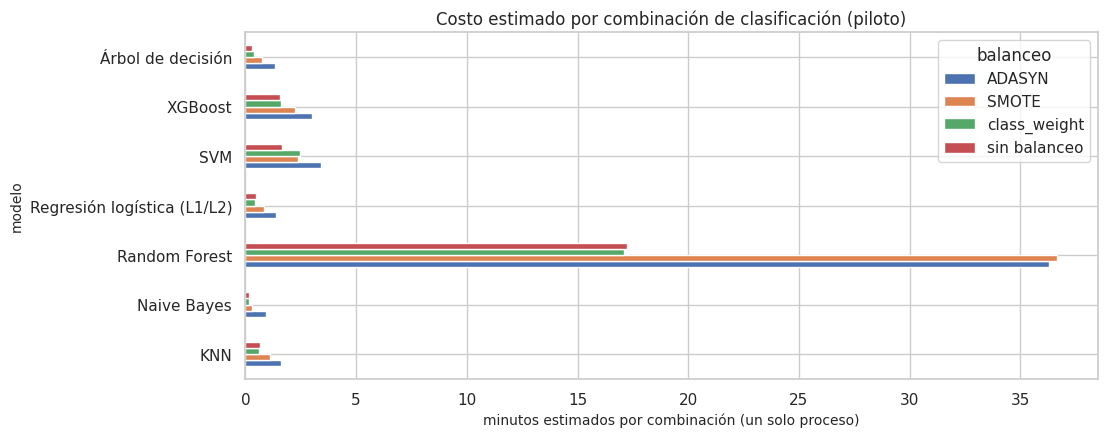

,tarea,modelo,balanceo,t_ajuste_s,t_pred_s,mem_pico_MB,costo_estimado_min
0,reg,KNN,—,0.07,0.28,12.00,0.81
1,reg,Ridge,—,0.05,0.01,11.83,0.15
2,reg,Lasso,—,0.09,0.02,12.72,0.25
3,reg,Árbol de decisión,—,0.15,0.02,11.82,0.37
4,reg,Random Forest,—,7.22,0.07,11.82,16.78
5,reg,XGBoost,—,0.53,0.03,11.82,1.30
6,reg,SVR,—,0.59,0.40,11.83,2.29
7,clf,KNN,sin balanceo,0.05,0.24,11.66,0.67
8,clf,KNN,SMOTE,0.13,0.35,16.55,1.11
9,clf,KNN,ADASYN,0.34,0.35,18.13,1.59


**Lectura del piloto.**
- **Costo total estimado** (un solo proceso): **regresión ≈ 1,5 h** y **clasificación ≈ 9,1 h**.
- **Random Forest** domina el costo, sobre todo con SMOTE/ADASYN, que casi duplican las filas. Le siguen XGBoost con
  sobremuestreo y SVM/SVR. Los modelos lineales, Naive Bayes y el árbol son casi gratis.
- **Memoria.** El pico fue de 18 MB por ajuste: la memoria no es la restricción, el tiempo sí.
- **Medida con Random Forest.** Se fijó `max_samples = 0,5` (cada árbol ve la mitad de las filas), que reduce su tiempo a la mitad
  sin cambiar la familia del modelo.


**Calibración con lo ya ejecutado.** 28 combinación(es) de regresión completada(s) en este entorno tardaron
293,9 min en total, frente a 87,8 min estimados (razón real/estimado =
3,35). El piloto se midió en el pliegue más grande y antes de fijar
`max_samples = 0,5` en Random Forest, así que **las estimaciones son conservadoras** (cotas superiores).

,modelo,optimizador,t_real_min,t_estimado_min
0,KNN,Bayesiano (TPE),1.23,0.81
1,KNN,Genético (DEAP),1.16,0.81
2,KNN,Grid,1.09,0.81
3,KNN,Random,1.15,0.81
4,Lasso,Bayesiano (TPE),0.15,0.25
5,Lasso,Genético (DEAP),0.14,0.25
6,Lasso,Grid,0.12,0.25
7,Lasso,Random,0.13,0.25
8,Random Forest,Bayesiano (TPE),56.71,16.78
9,Random Forest,Genético (DEAP),55.36,16.78


In [8]:
# Costo estimado por combinación (piloto) frente al costo real medido
piloto = pd.read_csv(BENCH / "piloto_costos.csv")
piloto["ajustes_por_combinación"] = 184
piloto["costo_estimado_min"] = (piloto.t_ajuste_s + piloto.t_pred_s) * 184 * 0.75 / 60   # 0,75: tamaño medio de los pliegues frente al mayor
hechos = []
for f_ in sorted((BENCH / "combos").glob("reg__*.pkl")):
    r = pd.read_pickle(f_)
    if r.get("estado") == "completado":
        hechos.append({"modelo": r["modelo"], "optimizador": r["optimizador"], "t_real_min": r["t_total_s"] / 60})
hechos = pd.DataFrame(hechos)
fig, ax = plt.subplots(figsize=(11, 4.5))
d = piloto[piloto.tarea == "clf"].pivot(index="modelo", columns="balanceo", values="costo_estimado_min")
d.plot.barh(ax=ax); ax.set_xlabel("minutos estimados por combinación (un solo proceso)")
ax.set_title("Costo estimado por combinación de clasificación (piloto)")
eda.guardar_figura(fig, "13_costos_piloto.png"); plt.show()
tot_clf = piloto[piloto.tarea == "clf"].costo_estimado_min.sum() * 4
tot_reg = piloto[piloto.tarea == "reg"].costo_estimado_min.sum() * 4
display(piloto[["tarea", "modelo", "balanceo", "t_ajuste_s", "t_pred_s", "mem_pico_MB", "costo_estimado_min"]].round(2))
md(f"""**Lectura del piloto.**
- **Costo total estimado** (un solo proceso): **regresión ≈ {es(tot_reg / 60, 1)} h** y **clasificación ≈ {es(tot_clf / 60, 1)} h**.
- **Random Forest** domina el costo, sobre todo con SMOTE/ADASYN, que casi duplican las filas. Le siguen XGBoost con
  sobremuestreo y SVM/SVR. Los modelos lineales, Naive Bayes y el árbol son casi gratis.
- **Memoria.** El pico fue de {es(piloto.mem_pico_MB.max(), 0)} MB por ajuste: la memoria no es la restricción, el tiempo sí.
- **Medida con Random Forest.** Se fijó `max_samples = 0,5` (cada árbol ve la mitad de las filas), que reduce su tiempo a la mitad
  sin cambiar la familia del modelo.
""")
if len(hechos):
    est_ = piloto[piloto.tarea == "reg"].set_index("modelo").costo_estimado_min
    hechos["t_estimado_min"] = hechos.modelo.map(est_)
    md(f"""**Calibración con lo ya ejecutado.** {len(hechos)} combinación(es) de regresión completada(s) en este entorno tardaron
{es(hechos.t_real_min.sum(), 1)} min en total, frente a {es(hechos.t_estimado_min.sum(), 1)} min estimados (razón real/estimado =
{es(hechos.t_real_min.sum() / hechos.t_estimado_min.sum(), 2)}). El piloto se midió en el pliegue más grande y antes de fijar
`max_samples = 0,5` en Random Forest, así que **las estimaciones son conservadoras** (cotas superiores).""")
    display(hechos.round(2))

## 13.6 Reducción 1: combinaciones equivalentes demostradas (no se corren)

- **KNN y Naive Bayes no tienen `class_weight`.** Su equivalente es corregir la probabilidad por la
  prevalencia de cada clase.
  - KNN: dividir la probabilidad por la prevalencia de la clase y renormalizar.
  - Naive Bayes: usar priors iguales (0,5; 0,5).
- **Esa corrección no cambia el orden de las predicciones.** En un problema binario el puntaje nuevo es
  p₁/π₁ / (p₁/π₁ + p₀/π₀), una **función monótona creciente** de p₁. Por lo tanto **el orden de las
  predicciones no cambia y la ROC-AUC (métrica principal) es idéntica** a la de «sin balanceo». Solo
  cambia el punto de corte, que equivale a mover el umbral de decisión sin reentrenar.
- **Consecuencia.** Correr esas 2 × 4 = **8 combinaciones** gastaría presupuesto en resultados que ya
  se conocen. Se demuestra con los datos:

In [9]:
# Efecto de class_weight en KNN y Naive Bayes sobre el ordenamiento (AUC)
a, v = ext[-1]
ia, iv = tr[a], tr[v]
dem = []
for mo, p in (("KNN", {"n_neighbors": 50, "weights": "uniform"}), ("Naive Bayes", {"var_smoothing": 1e-9})):
    s0 = bm.puntaje_clf(bm.construir("clf", mo, p, X.columns, "sin balanceo").fit(X.iloc[ia], yb[ia]), X.iloc[iv])
    s1 = bm.puntaje_clf(bm.construir("clf", mo, p, X.columns, "class_weight").fit(X.iloc[ia], yb[ia]), X.iloc[iv])
    dem.append({"modelo": mo, "AUC sin balanceo": bm.roc_auc_score(yb[iv], s0), "AUC class_weight (equivalente)": bm.roc_auc_score(yb[iv], s1),
                "Spearman entre puntajes": stats.spearmanr(s0, s1)[0],
                "recall@0,5 sin balanceo": np.mean(s0[yb[iv] == 1] >= 0.5), "recall@0,5 class_weight": np.mean(s1[yb[iv] == 1] >= 0.5)})
dem = pd.DataFrame(dem)
eda.guardar_tabla(dem, "equivalencia_class_weight.csv")
dem.round(6)

,modelo,AUC sin balanceo,AUC class_weight (equivalente),Spearman entre puntajes,"recall@0,5 sin balanceo","recall@0,5 class_weight"
0,KNN,0.779243,0.779243,1.0,0.241558,0.550649
1,Naive Bayes,0.785127,0.785127,1.0,0.405195,0.436364


In [10]:
md(f"""**Resultado.**
- **ROC-AUC idéntica.** Coincide hasta {('la sexta cifra decimal' if np.allclose(dem['AUC sin balanceo'], dem['AUC class_weight (equivalente)'], atol=1e-6) else 'tres decimales')} y la correlación de rangos entre puntajes
  es {es(dem['Spearman entre puntajes'].min(), 4)}.
- **Solo cambia lo que depende del umbral.** El recall con umbral 0,5 sube (por ejemplo, {es(dem['recall@0,5 sin balanceo'][0], 2)} → {es(dem['recall@0,5 class_weight'][0], 2)}
  en KNN), que es exactamente lo que se obtiene moviendo el umbral.
- **Decisión.** Se marcan como **«descartada a priori (equivalencia demostrada)»** y sus métricas de umbral se reportan con el umbral
  ajustado (capítulos siguientes).
- **Por qué no se extiende a los demás modelos.** En la regresión logística, el árbol, Random Forest, XGBoost y SVM, `class_weight`
  **cambia la función de pérdida** y por tanto el modelo ajustado, así que no hay equivalencia y se evalúan.""")

**Resultado.**
- **ROC-AUC idéntica.** Coincide hasta la sexta cifra decimal y la correlación de rangos entre puntajes
  es 1,0000.
- **Solo cambia lo que depende del umbral.** El recall con umbral 0,5 sube (por ejemplo, 0,24 → 0,55
  en KNN), que es exactamente lo que se obtiene moviendo el umbral.
- **Decisión.** Se marcan como **«descartada a priori (equivalencia demostrada)»** y sus métricas de umbral se reportan con el umbral
  ajustado (capítulos siguientes).
- **Por qué no se extiende a los demás modelos.** En la regresión logística, el árbol, Random Forest, XGBoost y SVM, `class_weight`
  **cambia la función de pérdida** y por tanto el modelo ajustado, así que no hay equivalencia y se evalúan.

## 13.7 Reducción 2: tamizaje de baja fidelidad (multi-fidelidad sobre combinaciones)

**Qué técnica de balanceo conviene a cada modelo.** No se puede saber sin datos: en el piloto, SMOTE
empeoró el árbol de decisión y mejoró el SVM. Se aplica la idea de **Successive Halving**
{cite}`li2018hyperband` a nivel de **pares (modelo, técnica de balanceo)**.

- **Fase 1 (baja fidelidad, para los 26 pares restantes).**
  - **Fidelidad:** solo el último pliegue externo (12 meses), Random Search con 5 evaluaciones y 2
    pliegues internos.
  - **Costo:** 11 ajustes por par en lugar de 184, ≈ **6 %** de una combinación completa.
  - **Por qué Random Search.** En el tamizaje el optimizador no es lo que se compara. Random Search es el
    estándar sin sesgo para muestrear el espacio.
- **Regla preregistrada para pasar a la fase 2** (`src/benchmark.py::seleccionar_fase2`). Por cada modelo pasan:
  1. **«sin balanceo»**, siempre: es la línea base contra la que la guía pide comparar el balanceo;
  2. la técnica de balanceo con **mayor ROC-AUC de tamizaje**;
  3. cualquier otra técnica a **menos de 0,005** de AUC de esa mejor (empate práctico; evita descartar por
     el ruido de un solo pliegue).
- **Fase 2 (fidelidad completa).** Los pares que pasan se corren con la **validación anidada completa**
  (sección 13.2) y con **los 4 optimizadores**, de modo que la comparación de optimizadores (la pregunta
  central de la guía) queda completa para cada par.
- **Factor de reducción.** De 4 técnicas por modelo pasan ≈ 2: un factor ≈ 2, el mismo de Successive
  Halving con η = 2.

**Lo que no se reduce:**
- los 7 modelos;
- los 4 optimizadores;
- el presupuesto de cada búsqueda;
- los pliegues;
- la regresión, cuyas 28 combinaciones se corren completas porque su costo total es moderado (sección 13.5).

**Lo que se reporta de lo descartado:** su AUC de tamizaje, su costo medido y el motivo, en la tabla
maestra (estado «descartada en tamizaje»).

In [11]:
# Tamizaje de clasificación: qué pares modelo × balanceo pasan a la fase completa
ruta_t = BENCH / "tamizaje_clasificacion.csv"
if ruta_t.exists():
    tam = bm.seleccionar_fase2(pd.read_csv(ruta_t))
    eda.guardar_tabla(tam, "tamizaje_clasificacion.csv")
    display(tam[["modelo", "balanceo", "AUC_tamizaje", "AP_tamizaje", "Recall_tamizaje", "t_total_s", "pasa_fase2", "motivo"]].round(4))
    pasan = tam[tam.pasa_fase2]
    md(f"**Resultado del tamizaje:** pasan **{len(pasan)} pares** → **{4 * len(pasan)} combinaciones** de clasificación en la fase 2 (de 112).")
else:
    md("**Tamizaje pendiente.** Se ejecuta con `python scripts/correr_experimentos.py --tarea clf --fase todo` (sección 13.9). Cuando el archivo "
       "`resultados/benchmark/tamizaje_clasificacion.csv` exista, esta celda mostrará qué pares pasan a la fase 2.")

,modelo,balanceo,AUC_tamizaje,AP_tamizaje,Recall_tamizaje,t_total_s,pasa_fase2,motivo
0,KNN,sin balanceo,0.7857,0.5661,0.2364,11.6437,True,línea base de balanceo (siempre pasa)
1,KNN,SMOTE,0.7830,0.5618,0.6519,14.6828,True,"mejor técnica de balanceo del modelo (o a < 0,..."
2,KNN,ADASYN,0.7784,0.5569,0.7065,18.3524,True,"mejor técnica de balanceo del modelo (o a < 0,..."
3,Naive Bayes,sin balanceo,0.7852,0.5412,0.4052,5.5752,True,línea base de balanceo (siempre pasa)
4,Naive Bayes,SMOTE,0.7854,0.5432,0.4364,6.7522,True,"mejor técnica de balanceo del modelo (o a < 0,..."
5,Naive Bayes,ADASYN,0.7873,0.5426,0.5013,4.5887,True,"mejor técnica de balanceo del modelo (o a < 0,..."
6,Random Forest,sin balanceo,0.7998,0.5911,0.2701,27.8586,True,línea base de balanceo (siempre pasa)
7,Random Forest,SMOTE,0.7939,0.5831,0.4364,64.8400,False,dominada: AUC 0.006 por debajo de la mejor téc...
8,Random Forest,ADASYN,0.7888,0.5758,0.4727,65.8515,False,dominada: AUC 0.011 por debajo de la mejor téc...
9,Random Forest,class_weight,0.7997,0.5899,0.5636,27.9035,True,"mejor técnica de balanceo del modelo (o a < 0,..."


**Resultado del tamizaje:** pasan **21 pares** → **84 combinaciones** de clasificación en la fase 2 (de 112).

## 13.8 Lista de combinaciones a ejecutar

In [12]:
# Las 140 combinaciones: tarea, modelo, balanceo, optimizador y fase
filas = []
for m in bm.MODELOS_REG:
    for o in bm.OPTIMIZADORES:
        filas.append({"tarea": "regresión", "modelo": m, "balanceo": "—", "optimizador": o, "fase": "completa (validación anidada)", "ajustes": 184})
for m in bm.MODELOS_CLF:
    for b in bm.BALANCEOS:
        if (m, b) in bm.EXCLUIDAS_A_PRIORI:
            for o in bm.OPTIMIZADORES:
                filas.append({"tarea": "clasificación", "modelo": m, "balanceo": b, "optimizador": o, "fase": "no se corre: equivalencia demostrada (13.6)", "ajustes": 0})
        else:
            filas.append({"tarea": "clasificación", "modelo": m, "balanceo": b, "optimizador": "Random (5 evaluaciones)", "fase": "fase 1: tamizaje", "ajustes": 11})
            for o in bm.OPTIMIZADORES:
                filas.append({"tarea": "clasificación", "modelo": m, "balanceo": b, "optimizador": o, "fase": "fase 2 si pasa el tamizaje", "ajustes": 184})
plan = pd.DataFrame(filas)
eda.guardar_tabla(plan, "plan_ejecucion.csv")
resumen_plan = plan.groupby(["tarea", "fase"]).agg(combinaciones=("modelo", "size"), ajustes=("ajustes", "sum")).reset_index()
display(resumen_plan)
costo = piloto.copy()
costo["par"] = list(zip(costo.modelo, costo.balanceo))
c_par = costo.set_index(["modelo", "balanceo"]).costo_estimado_min
fase2_max = sum(4 * c_par[(m, b)] for m in bm.MODELOS_CLF for b in bm.BALANCEOS if (m, b) not in bm.EXCLUIDAS_A_PRIORI) / 60
fase2_esp = sum(4 * min(c_par[(m, "sin balanceo")] + np.mean([c_par[(m, b)] for b in bm.BALANCEOS[1:] if (m, b) not in bm.EXCLUIDAS_A_PRIORI]), 1e9)
                for m in bm.MODELOS_CLF) / 60
md(f"""**Costo de clasificación (un solo proceso, estimado con el piloto).**
- **Diseño completo:** ≈ {es(tot_clf / 60, 2)} h.
- **Sin las 8 combinaciones equivalentes:** ≈ {es(fase2_max, 2)} h. Ahorran poco tiempo porque KNN y Naive Bayes son baratos; su
  justificación es **no producir resultados redundantes**, no el costo.
- **Con el tamizaje:** ≈ {es(c_par.sum() * 11 / 184 / 60, 2)} h de fase 1 + ≈ {es(fase2_esp, 1)} h de fase 2 esperada (dos técnicas por modelo).
  Con *P* procesos en paralelo, el tiempo se divide aproximadamente por *P*.""")
plan[plan.tarea == "clasificación"].head(12)

,tarea,fase,combinaciones,ajustes
0,clasificación,fase 1: tamizaje,26,286
1,clasificación,fase 2 si pasa el tamizaje,104,19136
2,clasificación,no se corre: equivalencia demostrada (13.6),8,0
3,regresión,completa (validación anidada),28,5152


**Costo de clasificación (un solo proceso, estimado con el piloto).**
- **Diseño completo:** ≈ 9,14 h.
- **Sin las 8 combinaciones equivalentes:** ≈ 9,09 h. Ahorran poco tiempo porque KNN y Naive Bayes son baratos; su
  justificación es **no producir resultados redundantes**, no el costo.
- **Con el tamizaje:** ≈ 0,16 h de fase 1 + ≈ 4,1 h de fase 2 esperada (dos técnicas por modelo).
  Con *P* procesos en paralelo, el tiempo se divide aproximadamente por *P*.

,tarea,modelo,balanceo,optimizador,fase,ajustes
28,clasificación,KNN,sin balanceo,Random (5 evaluaciones),fase 1: tamizaje,11
29,clasificación,KNN,sin balanceo,Grid,fase 2 si pasa el tamizaje,184
30,clasificación,KNN,sin balanceo,Random,fase 2 si pasa el tamizaje,184
31,clasificación,KNN,sin balanceo,Bayesiano (TPE),fase 2 si pasa el tamizaje,184
32,clasificación,KNN,sin balanceo,Genético (DEAP),fase 2 si pasa el tamizaje,184
33,clasificación,KNN,SMOTE,Random (5 evaluaciones),fase 1: tamizaje,11
34,clasificación,KNN,SMOTE,Grid,fase 2 si pasa el tamizaje,184
35,clasificación,KNN,SMOTE,Random,fase 2 si pasa el tamizaje,184
36,clasificación,KNN,SMOTE,Bayesiano (TPE),fase 2 si pasa el tamizaje,184
37,clasificación,KNN,SMOTE,Genético (DEAP),fase 2 si pasa el tamizaje,184


## 13.9 Cómo se ejecuta (reproducible, con puntos de control)

Desde la raíz del proyecto, con el entorno de `requirements.txt` (Python 3.9):

```bash
# Regresión: 28 combinaciones completas
python scripts/correr_experimentos.py --tarea reg --trabajos 2
# Clasificación: tamizaje (fase 1) y, a continuación, fase 2 con la regla preregistrada
python scripts/correr_experimentos.py --tarea clf --fase todo --trabajos N
# Aceleración por GPU de XGBoost (si hay GPU NVIDIA con CUDA)
python scripts/xgboost_gpu.py
```

- **Puntos de control.** Cada combinación se guarda en `resultados/benchmark/combos/*.pkl` y el tamizaje
  en `resultados/benchmark/tamizaje_clasificacion.csv`. Si la ejecución se interrumpe, al volver a
  lanzarla continúa donde iba.
- **Paralelismo.** `--trabajos N` reparte combinaciones entre N procesos (`joblib`, backend `loky`). Cada
  modelo usa un solo hilo para no anidar paralelismo, y las combinaciones más costosas se lanzan primero
  para equilibrar la carga.
- **Valor de N recomendado.** El número de núcleos físicos menos uno, siempre que haya ≈ 1 GB de RAM
  libre por proceso.
- **Tabla maestra.** `resultados/benchmark/experimentos_maestro.csv` tiene una fila por cada una de las
  140 combinaciones, con estado, hiperparámetros finales, métricas externas (media y desviación),
  tiempos, evaluaciones, semilla y motivo de descarte cuando aplica.

In [13]:
# Tabla maestra de experimentos (resultados/benchmark/experimentos_maestro.csv)
if (BENCH / "experimentos_maestro.csv").exists():
    corredor.tabla_maestra()
    tm_ = pd.read_csv(BENCH / "experimentos_maestro.csv")
    display(tm_.groupby(["tarea", "estado"]).size().rename("combinaciones").reset_index())

,tarea,estado,combinaciones
0,clf,completado,112
1,reg,completado,28


## 13.10 Decisión posterior: se ejecutaron las 140 combinaciones

Las reducciones de 13.6 y 13.7 se diseñaron para ahorrar cómputo con reglas fijadas antes de ver los
resultados. Al revisar el cumplimiento del enunciado (sección 2: *«7 × 4 × 4 = 112 modelos entrenados y
evaluados en clasificación»*), se decidió **ejecutar también las 28 combinaciones excluidas**, con exactamente
el mismo protocolo (`python scripts/correr_experimentos.py --tarea clf --fase 2 --todas`). Así:

- la tabla maestra tiene las **140 combinaciones completadas**, y la columna `decision_previa` conserva lo que
  las reglas habían decidido para cada una;
- las reducciones dejan de ser una exclusión y se convierten en un **experimento verificable**: el cap. 14.7
  compara lo que predijeron (equivalencia, bajo desempeño) con lo que pasó en la validación anidada completa;
- el ahorro de cómputo que habrían logrado se cuantifica con el tiempo real de las 28 combinaciones.

## 13.11 Evaluación final: origen móvil 2021–2026

La validación anidada (13.2) elige hiperparámetros y estima el desempeño **dentro del entrenamiento**. Para
medir cómo pronostica cada modelo meses que nunca vio se usa una evaluación de **origen móvil** sobre los meses
de enero de 2021 a septiembre de 2026 (69 meses), con la misma regla de siempre: un pronóstico solo puede usar
información disponible al cierre del mes anterior.

### Por qué no un único corte

El Entregable 1 separó los datos con un **corte único**: entrenar una vez con lo anterior a 2021 y evaluar todo
2021–2026 con ese modelo. Para la evaluación final se descarta ese esquema por tres razones:

- **No es como se usaría el modelo.** Un pronóstico sísmico operativo se actualiza a medida que llegan sismos
  nuevos. Con un corte único, el pronóstico de septiembre de 2026 lo haría un modelo que no ha visto nada
  posterior a 2020: casi seis años de catálogo sin usar.
- **La sismicidad no es estacionaria.** La tasa de sismos cambia por enjambres, secuencias de réplicas y
  cambios de régimen, y el propio catálogo cambia con la densificación de la red del SGC (KPSS rechaza la
  estacionariedad en nivel, cap. 7.4). Un modelo congelado no incorpora esos cambios, y su error mezclaría la
  calidad del modelo con lo desactualizado que está.
- **Depende de un único punto de partida.** Toda la comparación heredaría las particularidades de ese corte.

### Cómo funciona el origen móvil (*rolling origin*, ventana creciente)

Para cada año *Y* de 2021 a 2026:

1. se construye el panel con corte en enero de *Y* (celdas activas y normalizaciones solo con datos
   anteriores);
2. cada modelo se reentrena con **todo** el pasado disponible, con un mes de separación;
3. se pronostican los meses del año *Y*;
4. el origen avanza un año y se repite.

```text
2021:  entrenar [2005 ............. 2020] → pronosticar 2021
2022:  entrenar [2005 ............... 2021] → pronosticar 2022
 ...
2026:  entrenar [2005 ....................... 2025] → pronosticar 2026 (hasta septiembre)
```

Los hiperparámetros de todos los modelos se fijan **una sola vez** con datos anteriores a 2016 (15 evaluaciones
con validación temporal interna de 3 pliegues) y no cambian después; el mejor representante de cada familia (su
«campeón») se elige con esa misma validación. Nada de lo que se evalúa interviene en ninguna elección.

| | Corte único | Origen móvil |
|---|---|---|
| Reentrenamiento | una vez, con datos hasta 2020 | cada año, con todo el pasado |
| Pronóstico de 2026 hecho con datos hasta | 2020 | 2025 |
| Parecido al uso real | bajo | alto |
| Sensibilidad a la elección del corte | alta | menor: seis orígenes |

### Respaldo en la literatura

Es la forma estándar de evaluar pronósticos de series de tiempo y de sismos, no un recurso ad hoc:

- {cite}`tashman2000out`, en la revisión de referencia sobre pruebas fuera de muestra, concluye que los
  orígenes móviles, con recalibración de los modelos y varios periodos de prueba, hacen la evaluación **más
  eficiente y confiable** que un único origen fijo.
- {cite}`hyndman2021fpp3` (sección 5.10) la presentan como la validación propia de las series de tiempo:
  *evaluación sobre un origen de pronóstico móvil*, en la que el entrenamiento solo contiene observaciones
  anteriores a las que se pronostican.
- {cite}`cerqueira2020evaluating` comparan empíricamente métodos de estimación del desempeño en series reales y
  encuentran que, cuando la serie **no es estacionaria**, los métodos que respetan el orden temporal estiman
  mejor el error que la validación cruzada convencional.
- En sismología, el Collaboratory for the Study of Earthquake Predictability (CSEP) evalúa los modelos de
  pronóstico de forma **prospectiva**: el modelo se fija con datos del pasado y se juzga con los sismos que
  ocurren después {cite}`schorlemmer2018csep`. Cuando esos sismos ya ocurrieron, se hace una prueba
  **pseudoprospectiva**: se calibra con un periodo de aprendizaje y se pronostica el siguiente, sin usar
  información posterior {cite}`kiraly2016validating`. El origen móvil es una prueba pseudoprospectiva repetida
  año a año.

## 13.12 Combinaciones evaluadas en el origen móvil

Las **140 combinaciones** del enunciado se ejecutaron completas en la validación anidada (13.10, cap. 14). Para
la evaluación final en origen móvil se usan:

- **Regresión: las 28 combinaciones** (7 modelos × 4 optimizadores).
- **Clasificación: 26 combinaciones**, los 7 modelos × 4 técnicas de balanceo con optimización bayesiana (TPE),
  sin los dos pares equivalentes. La reducción se decidió antes de correr la evaluación y solo con evidencia
  anterior a 2021:
  - **Un optimizador (TPE) en lugar de cuatro.** En la validación anidada los cuatro optimizadores dan la misma
    métrica externa en clasificación (Friedman entre optimizadores, cap. 14.2) y TPE es el más eficiente por
    unidad de presupuesto (cap. 14.4). Repetir la evaluación con cuatro versiones del mismo modelo que llegan
    al mismo resultado no aporta información.
  - **Sin KNN ni Naive Bayes con class_weight.** Son equivalentes a «sin balanceo» en ROC-AUC (13.6; confirmado
    con la validación anidada completa en el cap. 14.7).

Así se conservan los 7 modelos y las 4 técnicas de balanceo, que es lo que comparan los capítulos 17 y 21
(`scripts/origen_movil_benchmark.py` y `scripts/origen_movil_clasificacion.py`).